# Racing Louisville 2026 — end-of-season stats exploration (ASA)

Starting point for the 2026 review, built almost entirely on the American Soccer Analysis API
(FBref no longer carries xG). Regular season only unless noted. Everything is pulled once and cached
in `cache/asa_cache.pkl`; set `REFRESH = True` to re-pull.

## Proposed highlights (first pass — to be refined)

**Team**
1. **7th to 15th.** 24 points from 30 games (7-3-20) after 37 from 26 in 2025. The underlying numbers agree it was bad (xGD 14th, np-xGD 14th, G+ difference 13th), though not quite *this* bad: xPoints was 31.8, so Racing ran about 8 points under expectation.
2. **The defense broke; the attack mostly held.** xG for per game was 1.36 (1.43 in 2025). xG against per game went from 1.34 to 1.87, the 7th-worst team-season in ASA's NWSL data. Shots against per game: 13.4 → 16.6.
3. **It was open play.** Open-play xG against roughly doubled (20.1 → 41.4; 0.77 → 1.38 per game). Fastbreak xGA also doubled. Corners went from 0 goals conceded to 7.
4. **Still the most direct team in the league, but the passing stopped working.** Lowest possession share in ASA's data (40.2%, below the 2025 record), longest average vertical pass distance again. But passes completed over expected flipped from +124 (5th) to −42 (15th), and opponents completed 434 more than expected (2nd most allowed).
5. **The press softened.** PPDA 6.6 (8th of 14) → 8.2 (12th of 16); defensive actions per game in the attacking two-thirds fell from 3rd to 8th. Interrupting value *for* was still #1, so the individual defending is there — it's what happens around it.
6. **The dead-ball attack shrank.** Corner + set-piece shots fell from 4.4 to 2.5 per game (1st in both → 9th and 11th). Total shots per game went from 1st in the league to 14th.
7. **Game state.** Conceded first in 19 of 30 (2-0-17 in those). First 15 minutes: 2 scored, 10 conceded. Final 15+: 17 conceded on 10.1 xG. 15 points dropped from winning positions.
8. **Three seasons in one.** Games 1–10: 7 pts. Games 11–20: 16 pts, including five wins in six from late July. Games 21–30: 1 pt, 8 scored, 25 conceded.
9. **Home/away split.** 18 points at home, 6 away (18 scored, 38 conceded on the road).
10. **Goalkeeping swing.** Bloomer went from +4.9 goals saved above expected (2nd; best per 90) to −4.2 (14th of 19): about a 9-goal swing on its own.

**Players — standouts**
- **Taylor Flint**: #1 of 40 DMs in G+ above average per 96, #1 DM in xG/90, 5 goals. Missed the last 8 games — but Racing was no better with her (0.78 ppg) than without (0.83).
- **Arin Wright** (4th of 52 CBs) and **Mirann Gacioch** (3rd of 52; #1 in the league in interrupting value). Racing took 1 point from the 6 games Wright missed.
- **Emma Sears**: 7 G / 5 A, 13th in the league in G+ above replacement, 5th among wingers in dribbling value. xG/90 dipped 0.29 → 0.25.
- **Kayla Fischer**: team-high 8 goals, #1 striker in interrupting value; last among strikers in pass completion vs expected.
- **Katie O'Kane**: second-most minutes, 4 G / 4 A, 2nd among DMs in xG+xA/90.
- **Quincy McMahon**: 7th of 51 FBs, 2nd among FBs in interrupting.
- **Maja Lardner**: 0.51 xG/90 in 705 minutes — 7th in the league among players with 500+ minutes — but 2 goals from 3.98 xG.

**Players — concerns**
- **Courtney Petersen at CB**: 50th of 52 (51st in interrupting) after a mid-table season at FB; still 7th among CBs in passing value.
- **Ellie Jean** 44th of 52 CBs; **Macey Hodge** 39th of 40 DMs; **Sarah Weber** 23rd of 26 STs; **Ella Hase** 0 G / 0 A in 1,400 minutes; **Makenna Morris** 43rd of 51 FBs.
- **Lauren Milliet**: led the team in minutes and assists (6) but 36th of 51 FBs by G+ (bottom-10 in interrupting and passing value).
- **What left**: DeMelo played 19 minutes all year. Sonis put up 12 G / 7 A for Denver. Borges went to Angel City.

**Caveat worth writing about**: the sum of Racing players' individual G+ above average is about the same as 2025 (−0.5 vs −1.3), while team G+ difference swung from +6 to −11. Individual G+ doesn't see the collapse, because it lives in the *against* columns (receiving and shooting value allowed) and in goal.

In [1]:
import os, pickle
import numpy as np
import pandas as pd
from plotnine import *
from itscalledsoccer.client import AmericanSoccerAnalysis

asa_client = AmericanSoccerAnalysis()
from sophso import *

pd.set_option("display.max_columns", 80)
pd.set_option("display.max_rows", 200)

LOU = "eV5DR6YQKn"
SEASONS = ["2025", "2026"]
RS = "Regular Season"
NP_PATTERNS = ["Set piece", "Corner", "Free kick", "Fastbreak", "Regular"]
ACTS = ["Dribbling", "Fouling", "Interrupting", "Passing", "Receiving", "Shooting"]
CACHE = "cache/asa_cache.pkl"
REFRESH = False

## Data pull (cached)

In [2]:
def pull():
    c, out = asa_client, {}
    out["teams"] = c.get_teams(leagues="nwsl")
    out["players"] = c.get_players(leagues="nwsl")
    for s in SEASONS:
        kw = dict(leagues="nwsl", season_name=s, stage_name=RS)
        out[f"games_{s}"] = c.get_games(leagues="nwsl", seasons=s)
        out[f"team_xg_{s}"] = c.get_team_xgoals(**kw)
        out[f"team_npxg_{s}"] = c.get_team_xgoals(**kw, shot_pattern=NP_PATTERNS)
        out[f"team_xg_games_{s}"] = c.get_team_xgoals(**kw, split_by_games=True)
        out[f"team_ga_{s}"] = c.get_team_goals_added(**kw)
        out[f"team_xpass_{s}"] = c.get_team_xpass(**kw)
        out[f"player_xg_{s}"] = c.get_player_xgoals(**kw)
        out[f"player_ga_{s}"] = c.get_player_goals_added(**kw)
        out[f"player_gar_{s}"] = c.get_player_goals_added(**kw, above_replacement=True)
        out[f"player_xpass_{s}"] = c.get_player_xpass(**kw)
        out[f"gk_xg_{s}"] = c.get_goalkeeper_xgoals(**kw)
        out[f"gk_ga_{s}"] = c.get_goalkeeper_goals_added(**kw)
        shots = c._get_stats(game_id=out[f"games_{s}"].game_id.to_list(), type="shots", entity="games", leagues="nwsl")
        shots["season"] = s
        out[f"shots_{s}"] = shots
        # for PPDA (same construction as eos25_asa.ipynb)
        out[f"team_ga_att23_{s}"] = c.get_team_goals_added(**kw, zone=[str(i) for i in np.arange(11, 31)])
        out[f"team_xpass_defmid_{s}"] = c.get_team_xpass(**kw, pass_origin_third=["Defensive", "Middle"])
    out["team_xpass_hist"] = c.get_team_xpass(leagues="nwsl", split_by_seasons=True, stage_name=RS)
    out["team_xg_hist"] = c.get_team_xgoals(leagues="nwsl", split_by_seasons=True, stage_name=RS)
    out["lou_player_games_2026"] = c.get_player_goals_added(leagues="nwsl", season_name="2026", stage_name=RS, split_by_games=True, team_ids=LOU)
    return out


if REFRESH or not os.path.exists(CACHE):
    d = pull()
    os.makedirs(os.path.dirname(CACHE), exist_ok=True)
    pickle.dump(d, open(CACHE, "wb"))
else:
    d = pickle.load(open(CACHE, "rb"))

tm = dict(zip(d["teams"].team_id, d["teams"].team_abbreviation))
pn = dict(zip(d["players"].player_id, d["players"].player_name))


def has_team(t, tid=LOU):
    return (tid in t) if isinstance(t, (list, np.ndarray)) else t == tid


def team_str(t):
    return "/".join(tm.get(x, x) for x in t) if isinstance(t, (list, np.ndarray)) else tm.get(t, t)


def explode_team_ga(df):
    rows = []
    for _, r in df.iterrows():
        row = {k: r[k] for k in df.columns if k != "data"}
        for a in r["data"]:
            for k, v in a.items():
                if k != "action_type":
                    row[f"{a['action_type']}_{k}"] = v
        rows.append(row)
    return pd.DataFrame(rows)


def rank_of(df, col, team="LOU", ascending=False):
    return int(df[col].rank(ascending=ascending, method="min")[df.team == team].iloc[0])

## 1. Team strength

Same measures as last year's summary table (minus the Opta/FBref rows). Lower-is-better columns are ranked ascending, so rank 1 is always best.

In [3]:
LOWER_BETTER = {"goals_against", "xgoals_against", "np_xgoals_against", "shots_against", "ga_against"}


def team_strength(s):
    x = d[f"team_xg_{s}"].copy()
    npx = d[f"team_npxg_{s}"][["team_id", "xgoals_for", "xgoals_against", "xgoal_difference"]]
    x = x.merge(npx.rename(columns=lambda c: c if c == "team_id" else "np_" + c), on="team_id")
    ga = explode_team_ga(d[f"team_ga_{s}"])
    ga["ga_for"] = ga[[c for c in ga.columns if c.endswith("goals_added_for")]].sum(axis=1)
    ga["ga_against"] = ga[[c for c in ga.columns if c.endswith("goals_added_against")]].sum(axis=1)
    ga["ga_diff"] = ga.ga_for - ga.ga_against
    x = x.merge(ga[["team_id", "ga_for", "ga_against", "ga_diff"]], on="team_id")
    x["team"] = x.team_id.map(tm)
    return x.sort_values("points", ascending=False).reset_index(drop=True)


strength = {s: team_strength(s) for s in SEASONS}
measures = ["points", "xpoints", "goal_difference", "xgoal_difference", "np_xgoal_difference", "xgoals_for", "xgoals_against",
            "np_xgoals_for", "np_xgoals_against", "shots_for", "shots_against", "ga_for", "ga_against", "ga_diff",
            "goal_difference_minus_xgoal_difference"]
rows = []
for m in measures:
    row = {"measure": m}
    for s in SEASONS:
        t = strength[s]
        lou = t[t.team == "LOU"].iloc[0]
        row[f"{s} value"] = round(lou[m], 2)
        row[f"{s} per game"] = round(lou[m] / lou["count_games"], 2)
        row[f"{s} rank"] = f"{rank_of(t, m, ascending=m in LOWER_BETTER)} of {len(t)}"
    rows.append(row)
pd.DataFrame(rows)

,measure,2025 value,2025 per game,2025 rank,2026 value,2026 per game,2026 rank
0,points,37.00,1.42,6 of 14,24.00,0.80,15 of 16
1,xpoints,37.92,1.46,6 of 14,31.81,1.06,14 of 16
2,goal_difference,-1.00,-0.04,8 of 14,-23.00,-0.77,15 of 16
3,xgoal_difference,2.14,0.08,7 of 14,-15.30,-0.51,14 of 16
4,np_xgoal_difference,4.65,0.18,4 of 14,-17.65,-0.59,14 of 16
5,xgoals_for,37.08,1.43,5 of 14,40.94,1.36,12 of 16
6,xgoals_against,34.95,1.34,9 of 14,56.24,1.87,14 of 16
7,np_xgoals_for,34.27,1.32,4 of 14,37.14,1.24,13 of 16
8,np_xgoals_against,29.62,1.14,5 of 14,54.79,1.83,15 of 16
9,shots_for,382.00,14.69,1 of 14,379.00,12.63,14 of 16


In [4]:
cols = ["team", "count_games", "points", "xpoints", "goals_for", "goals_against", "xgoals_for", "xgoals_against",
        "xgoal_difference", "np_xgoal_difference", "shots_for", "shots_against", "ga_diff"]
strength["2026"][cols].round(2)

,team,count_games,points,xpoints,goals_for,goals_against,xgoals_for,xgoals_against,xgoal_difference,np_xgoal_difference,shots_for,shots_against,ga_diff
0,NJY,30,61,47.90,38,23,46.37,36.44,9.94,9.66,385,326,3.08
1,SD,30,58,55.53,42,31,50.23,29.01,21.23,20.47,435,299,11.07
2,WAS,30,55,49.50,41,27,47.30,34.95,12.35,11.58,418,351,13.86
3,KC,30,53,52.05,52,37,56.66,37.17,19.50,19.50,409,365,15.48
4,LA,30,52,50.99,54,32,51.28,36.02,15.26,13.79,466,339,10.05
5,POR,30,50,43.97,49,40,47.59,43.06,4.53,-0.68,436,412,4.75
6,SEA,30,47,42.72,35,33,40.14,39.87,0.27,-0.54,396,406,10.88
7,UTA,30,47,43.16,43,39,42.00,40.23,1.77,1.02,397,339,1.88
8,NC,30,45,48.35,51,41,52.01,38.90,13.11,9.36,439,388,6.23
9,DEN,30,41,44.16,53,40,45.80,43.86,1.94,4.99,392,361,-1.05


Actual table from results (the xgoals endpoint's goal counts exclude own goals, so this is the one to quote for W-D-L and goals).

In [5]:
def actual_table(s):
    g = d[f"games_{s}"]
    g = g[~g.knockout_game.astype(bool)]
    rows = []
    for tid in pd.unique(pd.concat([g.home_team_id, g.away_team_id])):
        h, a = g[g.home_team_id == tid], g[g.away_team_id == tid]
        gf, ga = h.home_score.sum() + a.away_score.sum(), h.away_score.sum() + a.home_score.sum()
        w = (h.home_score > h.away_score).sum() + (a.away_score > a.home_score).sum()
        dr = (h.home_score == h.away_score).sum() + (a.away_score == a.home_score).sum()
        gp = len(h) + len(a)
        rows.append(dict(team=tm[tid], gp=gp, w=w, d=dr, l=gp - w - dr, gf=gf, ga=ga, gd=gf - ga, pts=3 * w + dr))
    t = pd.DataFrame(rows).sort_values(["pts", "gd"], ascending=False).reset_index(drop=True)
    t.index += 1
    return t


actual_table("2026")

,team,gp,w,d,l,gf,ga,gd,pts
1,NJY,30,18,7,5,39,23,16,61
2,SD,30,18,4,8,45,31,14,58
3,WAS,30,17,4,9,43,28,15,55
4,KC,30,16,5,9,54,39,15,53
5,LA,30,15,7,8,54,32,22,52
6,POR,30,14,8,8,50,41,9,50
7,UTA,30,14,5,11,44,39,5,47
8,SEA,30,14,5,11,37,33,4,47
9,NC,30,14,3,13,52,42,10,45
10,DEN,30,11,8,11,53,42,11,41


### Racing over time in ASA's data

In [6]:
xh = d["team_xg_hist"].copy()
xh["team"] = xh.team_id.map(tm)
for c in ["xgoals_for", "xgoals_against", "shots_for", "shots_against", "points", "xpoints"]:
    xh[c + "_pg"] = xh[c] / xh.count_games
display(xh[xh.team == "LOU"].sort_values("season_name")[["season_name", "count_games", "points_pg", "xpoints_pg", "xgoals_for_pg", "xgoals_against_pg", "shots_for_pg", "shots_against_pg"]].round(2))

print("Worst xG against per game, all NWSL team-seasons in ASA:")
xh.sort_values("xgoals_against_pg", ascending=False).head(8)[["team", "season_name", "count_games", "xgoals_against_pg", "shots_against_pg"]].round(2)

,season_name,count_games,points_pg,xpoints_pg,xgoals_for_pg,xgoals_against_pg,shots_for_pg,shots_against_pg
89,2021,24,0.92,0.87,0.96,1.80,8.92,17.50
90,2022,22,1.05,1.03,1.03,1.58,11.68,15.23
91,2023,22,1.23,1.21,1.32,1.57,14.55,15.95
92,2024,26,1.08,1.26,1.28,1.41,11.73,13.42
93,2025,26,1.42,1.46,1.43,1.34,14.69,13.42
94,2026,30,0.80,1.06,1.36,1.87,12.63,16.63


Worst xG against per game, all NWSL team-seasons in ASA:


,team,season_name,count_games,xgoals_against_pg,shots_against_pg
49,CHI,2026,30,2.21,18.23
65,ORL,2020,4,2.13,20.25
105,NJY,2018,24,2.10,17.25
46,CHI,2023,22,2.01,15.45
86,UTA,2024,26,1.96,14.35
14,HOU,2026,30,1.89,16.40
94,LOU,2026,30,1.87,16.63
12,HOU,2024,26,1.85,15.96


## 2. Where the value went: team goals added by action

`for` = value Racing created; `against` = value opponents created against Racing. Rank 1 = best in both.

In [7]:
rows = []
for s in SEASONS:
    ga = explode_team_ga(d[f"team_ga_{s}"])
    ga["team"] = ga.team_id.map(tm)
    for a in ACTS:
        ga[f"{a}_net"] = ga[f"{a}_goals_added_for"] - ga[f"{a}_goals_added_against"]
        lou = ga[ga.team == "LOU"].iloc[0]
        rows.append(dict(season=s, action=a,
                         g_for=round(lou[f"{a}_goals_added_for"], 2), for_rank=rank_of(ga, f"{a}_goals_added_for"),
                         g_against=round(lou[f"{a}_goals_added_against"], 2), against_rank=rank_of(ga, f"{a}_goals_added_against", ascending=True),
                         net=round(lou[f"{a}_net"], 2), net_rank=rank_of(ga, f"{a}_net"),
                         actions_for=lou[f"{a}_num_actions_for"], actions_rank=rank_of(ga, f"{a}_num_actions_for")))
pd.DataFrame(rows).pivot(index="action", columns="season").swaplevel(axis=1).sort_index(axis=1)

season              2025                                                      \
             actions_for actions_rank against_rank for_rank g_against  g_for   
action                                                                         
Dribbling           2753           14            6        8      0.66   0.60   
Fouling              298            7           13        4      2.46   2.19   
Interrupting        2941            2            1        7      9.01  13.43   
Passing             8469           14           14        1      4.11   6.52   
Receiving           5887           14            6        9     15.48  14.50   
Shooting             382            1            9        5      8.40   8.68   

season                             2026                                     \
               net net_rank actions_for actions_rank against_rank for_rank   
action                                                                       
Dribbling    -0.06        7        3359           16           14        6   
Fouling      -0.26        9         293           12            4        8   
Interrupting  4.43        1        3042            2            5        1   
Passing       2.41        5       10129           16           15        3   
Receiving    -0.98        8        7158           16           15       14   
Shooting      0.28        8         379           14           15       10   

season                                        
             g_against  g_for   net net_rank  
action                                        
Dribbling         7.00   4.68 -2.32       11  
Fouling           1.26   2.08  0.81        4  
Interrupting      9.73  15.17  5.44        3  
Passing           5.31   3.09 -2.22       13  
Receiving        24.24  14.46 -9.78       15  
Shooting         12.87   9.93 -2.94       14

## 3. Identity check: possession, directness, passing vs expectation

Possession here is share of attempted passes (the same proxy as last year's write-up).

In [8]:
h = d["team_xpass_hist"].copy()
h["team"] = h.team_id.map(tm)
h["poss"] = h.attempted_passes_for / (h.attempted_passes_for + h.attempted_passes_against)
style_cols = ["poss", "pass_completion_percentage_for", "xpass_completion_percentage_for", "passes_completed_over_expected_for",
              "passes_completed_over_expected_p100_for", "avg_vertical_distance_for", "avg_vertical_distance_difference",
              "passes_completed_over_expected_against", "passes_completed_over_expected_difference"]
display(h[h.team == "LOU"].sort_values("season_name")[["season_name"] + style_cols].round(3))

rows = []
for s in SEASONS:
    x = d[f"team_xpass_{s}"].copy()
    x["team"] = x.team_id.map(tm)
    x["poss"] = x.attempted_passes_for / (x.attempted_passes_for + x.attempted_passes_against)
    for c in style_cols:
        rows.append(dict(season=s, measure=c, rank=f"{rank_of(x, c)} of {len(x)}"))
display(pd.DataFrame(rows).pivot(index="measure", columns="season", values="rank").loc[style_cols])

print("Lowest possession share, all NWSL team-seasons in ASA:")
h.sort_values("poss").head(8)[["team", "season_name", "poss"]].round(3)

,season_name,poss,pass_completion_percentage_for,xpass_completion_percentage_for,passes_completed_over_expected_for,passes_completed_over_expected_p100_for,avg_vertical_distance_for,avg_vertical_distance_difference,passes_completed_over_expected_against,passes_completed_over_expected_difference
89,2021,0.464,0.723,0.735,-121.993,-1.163,8.312,1.172,255.813,-377.806
90,2022,0.490,0.702,0.707,-46.582,-0.507,8.603,0.356,-10.155,-36.427
91,2023,0.475,0.748,0.733,140.295,1.507,7.900,0.982,86.502,53.793
92,2024,0.468,0.780,0.763,197.328,1.688,6.287,0.957,145.883,51.445
93,2025,0.411,0.695,0.680,124.066,1.465,9.685,3.290,149.097,-25.031
94,2026,0.402,0.707,0.711,-42.070,-0.415,9.397,3.295,433.735,-475.804


season,2025,2026
measure,,
poss,14 of 14,16 of 16
pass_completion_percentage_for,14 of 14,16 of 16
xpass_completion_percentage_for,14 of 14,16 of 16
passes_completed_over_expected_for,5 of 14,15 of 16
passes_completed_over_expected_p100_for,5 of 14,15 of 16
avg_vertical_distance_for,1 of 14,1 of 16
avg_vertical_distance_difference,1 of 14,1 of 16
passes_completed_over_expected_against,4 of 14,2 of 16
passes_completed_over_expected_difference,9 of 14,15 of 16


Lowest possession share, all NWSL team-seasons in ASA:


,team,season_name,poss
94,LOU,2026,0.402
6,HOU,2018,0.407
93,LOU,2025,0.411
47,CHI,2024,0.420
85,UTA,2020,0.435
44,CHI,2021,0.445
49,CHI,2026,0.446
106,NJY,2019,0.448


### Pressing: PPDA and defensive actions (same construction as `eos25_asa.ipynb`)

In [9]:
def ppda(s):
    rows = []
    for _, r in d[f"team_ga_att23_{s}"].iterrows():
        row = dict(team_id=r.team_id)
        for a in r["data"]:
            row[a["action_type"]] = a["num_actions_for"]
        rows.append(row)
    g = pd.DataFrame(rows).merge(d[f"team_xpass_defmid_{s}"][["team_id", "attempted_passes_against", "count_games"]], on="team_id")
    g["team"] = g.team_id.map(tm)
    g["ppda"] = g.attempted_passes_against / (g.Interrupting + g.Fouling)
    g["def_actions_pg"] = (g.Interrupting + g.Fouling) / g.count_games
    g["ppda_rank"] = g.ppda.rank(method="min").astype(int)
    g["def_actions_rank"] = g.def_actions_pg.rank(ascending=False, method="min").astype(int)
    return g.sort_values("ppda")[["team", "ppda", "ppda_rank", "def_actions_pg", "def_actions_rank"]].round(2).reset_index(drop=True)


display(ppda("2025"), ppda("2026"))

,team,ppda,ppda_rank,def_actions_pg,def_actions_rank
0,NJY,5.61,1,56.35,1
1,UTA,5.67,2,51.35,9
2,WAS,5.99,3,52.46,8
3,LA,6.11,4,53.54,5
4,SD,6.20,5,49.27,13
5,HOU,6.50,6,53.08,7
6,ORL,6.51,7,50.08,11
7,LOU,6.60,8,54.62,3
8,NC,6.73,9,50.00,12
9,POR,6.73,10,53.31,6


,team,ppda,ppda_rank,def_actions_pg,def_actions_rank
0,NJY,5.80,1,52.70,1
1,UTA,6.10,2,48.10,6
2,WAS,6.62,3,48.33,5
3,BOS,6.84,4,48.10,6
4,SD,7.16,5,47.10,9
5,KC,7.28,6,50.93,2
6,LA,7.28,7,45.77,11
7,SEA,7.33,8,49.53,3
8,BAY,7.42,9,45.00,12
9,NC,7.58,10,48.83,4


## 4. The season game by game

In [10]:
g26 = d["games_2026"].copy()
g26["date"] = pd.to_datetime(g26.date_time_utc)
lg = d["team_xg_games_2026"]
lg = lg[lg.team_id == LOU].merge(g26[["game_id", "date", "home_team_id", "away_team_id", "home_score", "away_score"]], on="game_id").sort_values("date").reset_index(drop=True)
lg["n"] = lg.index + 1
lg["home"] = lg.home_team_id == LOU
lg["opp"] = np.where(lg.home, lg.away_team_id, lg.home_team_id)
lg["opp"] = lg.opp.map(tm)
lg["score"] = np.where(lg.home, lg.home_score.astype(str) + "-" + lg.away_score.astype(str), lg.away_score.astype(str) + "-" + lg.home_score.astype(str))
lg[["n", "date", "opp", "home", "score", "points", "xpoints", "xgoals_for", "xgoals_against", "xgoal_difference", "shots_for", "shots_against"]].round(2)

,n,date,opp,home,score,points,xpoints,xgoals_for,xgoals_against,xgoal_difference,shots_for,shots_against
0,1,2026-03-14 23:00:00+00:00,NC,False,1-2,0,1.89,2.14,1.39,0.74,17,14
1,2,2026-03-21 00:00:00+00:00,WAS,True,2-2,1,0.57,0.60,1.53,-0.93,8,21
2,3,2026-03-28 22:30:00+00:00,SEA,False,1-2,0,2.19,1.75,0.63,1.12,20,6
3,4,2026-04-04 00:30:00+00:00,HOU,False,3-4,0,0.92,2.76,3.35,-0.59,8,24
4,5,2026-04-24 21:30:00+00:00,ORL,True,3-2,3,0.56,1.11,2.48,-1.36,11,27
5,6,2026-04-29 23:00:00+00:00,WAS,False,0-1,0,0.37,0.42,1.67,-1.25,6,13
6,7,2026-05-03 21:00:00+00:00,NJY,False,0-1,0,0.72,0.81,1.65,-0.84,6,14
7,8,2026-05-08 22:30:00+00:00,POR,True,3-1,3,1.63,1.72,1.29,0.42,20,14
8,9,2026-05-18 00:00:00+00:00,UTA,False,1-2,0,0.56,0.73,2.02,-1.29,8,18
9,10,2026-05-23 20:00:00+00:00,NC,True,1-2,0,1.46,1.68,1.50,0.18,18,11


In [11]:
def chunk(lbl, s_):
    return dict(span=lbl, games=len(s_), pts=s_.points.sum(), xpts=round(s_.xpoints.sum(), 1), gf=s_.goals_for.sum(), ga=s_.goals_against.sum(),
                xgf=round(s_.xgoals_for.sum(), 1), xga=round(s_.xgoals_against.sum(), 1), shots_for=s_.shots_for.sum(), shots_against=s_.shots_against.sum())


pd.DataFrame([chunk("games 1-10", lg.iloc[:10]), chunk("games 11-20", lg.iloc[10:20]), chunk("games 21-30", lg.iloc[20:]),
              chunk("home", lg[lg.home]), chunk("away", lg[~lg.home])])

,span,games,pts,xpts,gf,ga,xgf,xga,shots_for,shots_against
0,games 1-10,10,7,10.9,15,18,13.7,17.5,122,162
1,games 11-20,10,16,12.0,15,18,15.4,19.2,141,157
2,games 21-30,10,1,8.9,8,25,11.8,19.5,116,180
3,home,15,18,17.9,20,23,20.6,25.4,185,227
4,away,15,6,13.9,18,38,20.4,30.9,194,272


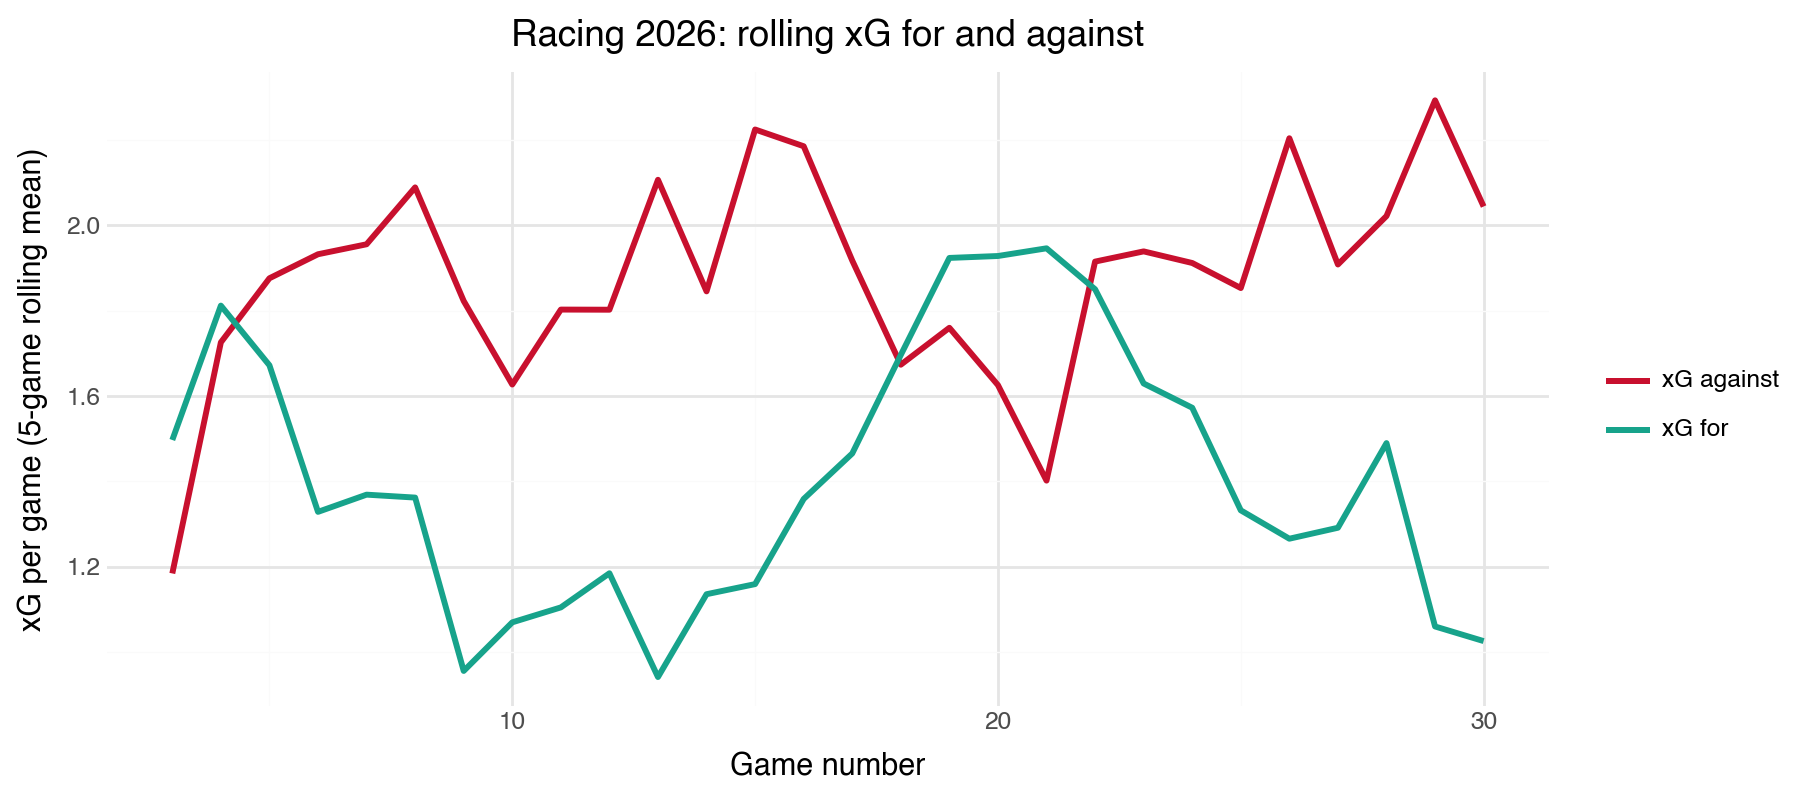

In [12]:
roll = lg[["n", "xgoals_for", "xgoals_against"]].copy()
roll["xG for"] = roll.xgoals_for.rolling(5, min_periods=3).mean()
roll["xG against"] = roll.xgoals_against.rolling(5, min_periods=3).mean()
(
    ggplot(roll.melt(id_vars="n", value_vars=["xG for", "xG against"]).dropna(), aes("n", "value", color="variable"))
    + geom_line(size=1.2)
    + scale_color_manual(values={"xG for": "#17a38b", "xG against": "#c8102e"})
    + labs(x="Game number", y="xG per game (5-game rolling mean)", color="", title="Racing 2026: rolling xG for and against")
    + theme_minimal()
    + theme(figure_size=(9, 4))
)

## 5. Shots: how goals were created and conceded

Shots feed has no own goals. `pattern_of_play` ranks: 1 = most for / fewest against.

In [13]:
def prep_shots(s):
    g = d[f"games_{s}"]
    g = g[~g.knockout_game.astype(bool)]
    sh = d[f"shots_{s}"]
    sh = sh[sh.game_id.isin(g.game_id)].copy()
    opp = {}
    for _, r in g.iterrows():
        opp[(r.game_id, r.home_team_id)] = r.away_team_id
        opp[(r.game_id, r.away_team_id)] = r.home_team_id
    sh["team"] = sh.team_id.map(tm)
    sh["opp"] = [tm[opp[(a, b)]] for a, b in zip(sh.game_id, sh.team_id)]
    sh["bin"] = pd.cut(sh.game_minute.clip(upper=89), [-1, 14, 29, 44, 59, 74, 89], labels=["0-14", "15-29", "30-44", "45-59", "60-74", "75-90+"])
    sh.loc[(sh.period_id == 1) & (sh.game_minute >= 45), "bin"] = "30-44"
    return g, sh


shots = {s: prep_shots(s) for s in SEASONS}

rows = []
for s in SEASONS:
    g, sh = shots[s]
    n_games = 26 if s == "2025" else 30
    for side, key, asc in [("for", "team", False), ("against", "opp", True)]:
        t = sh.groupby([key, "pattern_of_play"]).agg(shots=("goal", "size"), goals=("goal", "sum"), xg=("shot_xg", "sum")).reset_index()
        t["xg_rank"] = t.groupby("pattern_of_play").xg.rank(ascending=asc, method="min")
        for _, r in t[t[key] == "LOU"].iterrows():
            rows.append(dict(season=s, side=side, pattern=r.pattern_of_play, shots=r.shots, shots_pg=round(r.shots / n_games, 2), goals=r.goals, xg=round(r.xg, 2), xg_pg=round(r.xg / n_games, 2), xg_rank=int(r.xg_rank)))
pd.DataFrame(rows).pivot(index=["side", "pattern"], columns="season").swaplevel(axis=1).sort_index(axis=1)

season             2025                                      2026        \
                  goals shots shots_pg     xg xg_pg xg_rank goals shots   
side    pattern                                                           
against Corner        0    53     2.04   3.13  0.12       4     7    59   
        Fastbreak     4    17     0.65   2.97  0.11       6     5    29   
        Free kick     3     8     0.31   0.61  0.02      13     0     5   
        Penalty       3     7     0.27   5.34  0.21      14     2     2   
        Regular      22   244     9.38  20.13  0.77       6    45   394   
        Set piece     3    20     0.77   3.28  0.13      14     2    10   
for     Corner        6    75     2.88   6.33  0.24       1     4    58   
        Fastbreak     1    20     0.77   3.21  0.12       7     3    29   
        Free kick     1     8     0.31   0.42  0.02       4     1    10   
        Penalty       4     4     0.15   3.05  0.12       5     5     5   
        Regular      20   236     9.08  22.70  0.87       6    23   261   
        Set piece     2    39     1.50   3.02  0.12       3     2    16   

season                                           
                  shots_pg     xg xg_pg xg_rank  
side    pattern                                  
against Corner        1.97   6.37  0.21      13  
        Fastbreak     0.97   6.71  0.22      14  
        Free kick     0.17   0.26  0.01       3  
        Penalty       0.07   1.52  0.05       4  
        Regular      13.13  41.40  1.38      15  
        Set piece     0.33   1.18  0.04       6  
for     Corner        1.93   5.83  0.19       4  
        Fastbreak     0.97   4.01  0.13      10  
        Free kick     0.33   0.61  0.02       2  
        Penalty       0.17   3.81  0.13       6  
        Regular       8.70  27.07  0.90      11  
        Set piece     0.53   1.76  0.06       7

In [14]:
rows = []
for s in SEASONS:
    g, sh = shots[s]
    q = sh.groupby("team").agg(xg_per_shot=("shot_xg", "mean"), head_share=("head", "mean")).reset_index()
    q = q.merge(sh.groupby("opp").agg(xga_per_shot=("shot_xg", "mean")).reset_index().rename(columns={"opp": "team"}))
    q = q.merge(sh.assign(sot=sh.shot_psxg > 0).groupby("team").sot.mean().rename("sot_rate").reset_index())
    hd = sh[sh["head"] == 1]
    q = q.merge(hd.groupby("team").agg(header_goals=("goal", "sum"), header_xg=("shot_xg", "sum")).reset_index())
    q = q.merge(hd.groupby("opp").agg(header_goals_against=("goal", "sum")).reset_index().rename(columns={"opp": "team"}))
    for c, asc in [("xg_per_shot", False), ("xga_per_shot", True), ("sot_rate", False), ("head_share", False), ("header_goals", False), ("header_xg", False), ("header_goals_against", True)]:
        rows.append(dict(season=s, measure=c, value=round(q[c][q.team == "LOU"].iloc[0], 3), rank=f"{rank_of(q, c, ascending=asc)} of {len(q)}"))
pd.DataFrame(rows).pivot(index="measure", columns="season").swaplevel(axis=1).sort_index(axis=1)

season                    2025             2026       
                          rank  value      rank  value
measure                                               
head_share             1 of 14  0.220   3 of 16  0.174
header_goals           3 of 14  7.000   1 of 16  7.000
header_goals_against   4 of 14  4.000  13 of 16  7.000
header_xg              1 of 14  8.263   4 of 16  7.332
sot_rate              14 of 14  0.306  16 of 16  0.288
xg_per_shot           10 of 14  0.101   7 of 16  0.114
xga_per_shot           4 of 14  0.102   9 of 16  0.115

### When goals came, and game state

In [15]:
for s in SEASONS:
    g, sh = shots[s]
    tf = sh[sh.team == "LOU"].groupby("bin", observed=False).agg(gf=("goal", "sum"), xgf=("shot_xg", "sum"))
    ta = sh[sh.opp == "LOU"].groupby("bin", observed=False).agg(ga=("goal", "sum"), xga=("shot_xg", "sum"))
    t = tf.join(ta)
    t["gd"], t["xgd"] = t.gf - t.ga, t.xgf - t.xga
    allb = sh.groupby(["team", "bin"], observed=False).shot_xg.sum().rename("f").reset_index().merge(
        sh.groupby(["opp", "bin"], observed=False).shot_xg.sum().rename("a").reset_index().rename(columns={"opp": "team"}))
    allb["xgd"] = allb.f - allb.a
    allb["rk"] = allb.groupby("bin", observed=False).xgd.rank(ascending=False, method="min")
    t["xgd_rank"] = allb[allb.team == "LOU"].set_index("bin").rk.astype(int)
    print(s)
    display(t.round(2))

2025


,gf,xgf,ga,xga,gd,xgd,xgd_rank
bin,,,,,,,
0-14,3,3.62,6,4.58,-3,-0.96,9
15-29,7,8.87,3,3.43,4,5.44,2
30-44,4,8.57,8,7.72,-4,0.85,5
45-59,7,6.38,5,5.02,2,1.37,5
60-74,7,6.36,5,5.81,2,0.55,6
75-90+,6,4.95,8,8.91,-2,-3.95,13


2026


,gf,xgf,ga,xga,gd,xgd,xgd_rank
bin,,,,,,,
0-14,2,3.83,10,9.82,-8,-5.99,15
15-29,9,8.97,7,8.04,2,0.94,5
30-44,5,6.66,7,9.97,-2,-3.31,13
45-59,9,9.54,13,12.02,-4,-2.48,14
60-74,5,5.53,7,7.46,-2,-1.93,10
75-90+,8,8.54,17,10.13,-9,-1.59,9


In [16]:
def game_state(s):
    g, sh = shots[s]
    goals = sh[sh.goal == 1].sort_values(["game_id", "period_id", "expanded_minute"])
    lgames = g[(g.home_team_id == LOU) | (g.away_team_id == LOU)]
    rec = {"scored first": [0, 0, 0, 0], "conceded first": [0, 0, 0, 0]}
    led = trailed = dropped = gained = 0
    for _, r in lgames.iterrows():
        home = r.home_team_id == LOU
        gf, ga = (r.home_score, r.away_score) if home else (r.away_score, r.home_score)
        pts = 3 if gf > ga else 1 if gf == ga else 0
        diff, was_up, was_down, first = 0, False, False, None
        for _, e in goals[goals.game_id == r.game_id].iterrows():
            diff += 1 if e.team == "LOU" else -1
            first = first or ("scored first" if e.team == "LOU" else "conceded first")
            was_up |= diff > 0
            was_down |= diff < 0
        if first:
            rec[first][0] += 1
            rec[first][{3: 1, 1: 2, 0: 3}[pts]] += 1
        led += was_up
        trailed += was_down
        dropped += (3 - pts) * was_up
        gained += pts * was_down
    out = pd.DataFrame(rec, index=["games", "W", "D", "L"]).T
    print(f"{s}: led in {led} games, dropped {dropped} points from winning positions; trailed in {trailed}, took {gained} points")
    pen = sh[sh.pattern_of_play == "Penalty"]
    print(f"   penalties for {len(pen[pen.team == 'LOU'])} (scored {pen[pen.team == 'LOU'].goal.sum()}), against {len(pen[pen.opp == 'LOU'])} (conceded {pen[pen.opp == 'LOU'].goal.sum()})")
    return out


for s in SEASONS:
    display(game_state(s))

2025: led in 16 games, dropped 13 points from winning positions; trailed in 13, took 9 points
   penalties for 4 (scored 4), against 7 (conceded 3)


,games,W,D,L
scored first,13,8,4,1
conceded first,13,2,3,8


2026: led in 13 games, dropped 15 points from winning positions; trailed in 21, took 6 points
   penalties for 5 (scored 5), against 2 (conceded 2)


,games,W,D,L
scored first,11,5,3,3
conceded first,19,2,0,17


## 6. Players

- **G+ above average** is ASA's goals added relative to the average player *at the same position* (this is the position-weighted G+), shown per 96 minutes.
- Ranks are among players with at least 25% of the league-high minutes (same qualification rule as last year's FBref tables): `lg` = whole league, `pos` = within ASA's general position.
- ASA's player xG includes penalties.

In [17]:
def build_players(season):
    rows = []
    for _, r in d[f"player_ga_{season}"].iterrows():
        row = dict(player_id=r.player_id, team_id=r.team_id, pos=r.general_position, minutes=r.minutes_played)
        for a in r["data"]:
            row[f"{a['action_type']}_aa"] = a["goals_added_above_avg"]
            row[f"{a['action_type']}_raw"] = a["goals_added_raw"]
        rows.append(row)
    df = pd.DataFrame(rows).fillna(0)
    df["ga_aa"] = df[[f"{a}_aa" for a in ACTS]].sum(axis=1)
    df["ga_raw"] = df[[f"{a}_raw" for a in ACTS]].sum(axis=1)
    df = df.merge(d[f"player_gar_{season}"][["player_id", "goals_added_above_replacement"]].rename(columns={"goals_added_above_replacement": "gar"}), on="player_id", how="left")
    df = df.merge(d[f"player_xg_{season}"].drop(columns=["team_id", "general_position", "minutes_played"]), on="player_id", how="left")
    df = df.merge(d[f"player_xpass_{season}"].drop(columns=["team_id", "general_position", "minutes_played", "count_games"]), on="player_id", how="left")
    df["name"], df["team"], df["lou"] = df.player_id.map(pn), df.team_id.apply(team_str), df.team_id.apply(has_team)
    m = df.minutes
    df["ga_aa_p96"] = df.ga_aa / m * 96
    df["xg_p90"], df["xa_p90"], df["xgxa_p90"] = df.xgoals / m * 90, df.xassists / m * 90, df.xgoals_plus_xassists / m * 90
    df["shots_p90"], df["kp_p90"] = df.shots / m * 90, df.key_passes / m * 90
    df["qual"] = m >= m.max() / 4
    q = df[df.qual]
    rank_cols = ["ga_aa_p96", "ga_aa", "gar", "xg_p90", "xa_p90", "xgxa_p90", "shots_p90", "kp_p90", "goals_minus_xgoals", "passes_completed_over_expected_p100"] + [f"{a}_aa" for a in ACTS]
    for c in rank_cols:
        df[f"{c}_lg"] = q[c].rank(ascending=False, method="min")
        df[f"{c}_pos"] = q.groupby("pos")[c].rank(ascending=False, method="min")
    df["n_pos"] = df.pos.map(q.pos.value_counts())
    df.attrs["n_qual"] = len(q)
    return df


players = {s: build_players(s) for s in SEASONS}
fmt = lambda v: "" if pd.isna(v) else str(int(v))


def racing_table(season):
    df = players[season]
    l = df[df.lou].sort_values("minutes", ascending=False)
    out = pd.DataFrame({
        "player": l.name, "team": l.team, "pos": l.pos, "min": l.minutes,
        "G+ aa": l.ga_aa.round(2), "G+ aa/96": l.ga_aa_p96.round(3),
        "G+ lg rank": l.ga_aa_p96_lg.map(fmt), "G+ pos rank": l.ga_aa_p96_pos.map(fmt) + "/" + l.n_pos.map(fmt),
        "GAR": l.gar.round(2), "GAR lg rank": l.gar_lg.map(fmt),
        "G": l.goals, "xG": l.xgoals.round(2), "G-xG": l.goals_minus_xgoals.round(2), "A": l.primary_assists, "xA": l.xassists.round(2),
        "xG/90": l.xg_p90.round(2), "xG/90 lg (pos)": l.xg_p90_lg.map(fmt) + " (" + l.xg_p90_pos.map(fmt) + ")",
        "xG+xA/90": l.xgxa_p90.round(2), "xG+xA/90 lg (pos)": l.xgxa_p90_lg.map(fmt) + " (" + l.xgxa_p90_pos.map(fmt) + ")",
        "xA/90 lg (pos)": l.xa_p90_lg.map(fmt) + " (" + l.xa_p90_pos.map(fmt) + ")",
    }).reset_index(drop=True)
    print(f"{season}: {df.attrs['n_qual']} qualified players; by position {df[df.qual].pos.value_counts().to_dict()}")
    return out


racing_table("2026")

2026: 241 qualified players; by position {'CB': 52, 'FB': 51, 'W': 45, 'DM': 40, 'ST': 26, 'AM': 16, 'CM': 11}


,player,team,pos,min,G+ aa,G+ aa/96,G+ lg rank,G+ pos rank,GAR,GAR lg rank,G,xG,G-xG,A,xA,xG/90,xG/90 lg (pos),xG+xA/90,xG+xA/90 lg (pos),xA/90 lg (pos)
0,Lauren Milliet,LOU,FB,2850,-1.32,-0.044,172,36/51,2.28,103,3,3.34,-0.34,6,4.00,0.11,94 (5),0.23,89 (6),59 (10)
1,Katie O'Kane,LOU,DM,2687,-0.33,-0.012,114,11/40,3.11,69,4,4.32,-0.32,4,3.75,0.14,75 (3),0.27,70 (2),61 (4)
2,Arin Wright,LOU,CB,2445,2.27,0.089,23,4/52,4.42,34,1,1.62,-0.62,2,0.77,0.06,144 (13),0.09,166 (7),188 (15)
3,Kayla Fischer,LOU,ST,2381,0.76,0.031,58,8/26,5.36,18,8,6.78,1.22,3,2.03,0.26,48 (21),0.33,59 (22),109 (17)
4,Emma Sears,LOU,W,2249,1.91,0.081,26,12/45,6.38,13,7,6.20,0.80,5,3.52,0.25,52 (22),0.39,48 (22),49 (23)
5,Ellie Jean,LOU,CB,2048,-1.19,-0.056,181,44/52,0.61,204,0,0.05,-0.05,0,0.37,0.00,239 (51),0.02,236 (49),204 (23)
6,Taylor Flint,LOU,DM,1868,1.54,0.079,28,1/40,3.57,52,5,4.42,0.58,0,0.50,0.21,57 (1),0.24,84 (4),193 (34)
7,Quincy McMahon,LOU,FB,1780,0.66,0.036,53,7/51,2.32,100,0,1.06,-1.06,0,1.22,0.05,154 (25),0.12,149 (28),131 (31)
8,Courtney Petersen,LOU,CB,1777,-1.62,-0.088,214,50/52,-0.05,233,0,1.21,-1.21,0,1.85,0.06,140 (12),0.16,117 (1),85 (1)
9,Mirann Gacioch,LOU,CB,1686,1.57,0.089,22,3/52,3.05,71,1,0.82,0.18,0,0.24,0.04,166 (17),0.06,198 (23),210 (28)


In [18]:
racing_table("2025")

2025: 215 qualified players; by position {'FB': 45, 'CB': 43, 'W': 42, 'CM': 28, 'ST': 25, 'DM': 23, 'AM': 9}


,player,team,pos,min,G+ aa,G+ aa/96,G+ lg rank,G+ pos rank,GAR,GAR lg rank,G,xG,G-xG,A,xA,xG/90,xG/90 lg (pos),xG+xA/90,xG+xA/90 lg (pos),xA/90 lg (pos)
0,Emma Sears,LOU,W,2514,1.27,0.048,27,10/42,6.13,4,10,8.15,1.85,2,2.20,0.29,20 (9),0.37,29 (13),89 (34)
1,Courtney Petersen,LOU,FB,2355,-0.61,-0.025,108,22/45,1.48,116,0,0.38,-0.38,3,2.54,0.01,186 (33),0.11,129 (16),64 (8)
2,Ellie Jean,LOU,CB,2354,-0.64,-0.026,114,30/43,1.42,120,1,0.83,0.17,0,0.17,0.03,167 (25),0.04,194 (28),202 (30)
3,Taylor Flint,LOU,DM,2349,1.02,0.042,34,4/23,3.51,30,4,4.03,-0.03,0,0.70,0.15,68 (3),0.18,99 (8),164 (20)
4,Janine Sonis,LOU,FB,2335,0.12,0.005,66,14/45,3.42,31,3,1.51,1.49,5,3.98,0.06,118 (12),0.21,89 (4),21 (2)
5,Arin Wright,LOU,CB,2162,-0.09,-0.004,77,17/43,1.80,98,1,0.85,0.15,2,0.85,0.04,156 (19),0.07,155 (7),150 (6)
6,Lauren Milliet,LOU,FB,1736,0.22,0.012,59,12/45,1.86,95,0,0.36,-0.36,1,1.37,0.02,178 (30),0.09,140 (22),102 (17)
7,Ella Hase,LOU,W,1678,-0.73,-0.042,150,37/42,2.14,75,1,1.81,-0.81,1,2.43,0.10,96 (40),0.23,83 (38),37 (19)
8,Ary Borges,LOU,CM,1602,0.58,0.035,41,4/28,2.71,51,1,3.98,-2.98,0,0.23,0.22,38 (5),0.24,72 (8),189 (28)
9,Sarah Weber,LOU,ST,1569,-0.44,-0.027,115,14/25,2.69,52,3,4.31,-1.31,1,0.86,0.25,32 (15),0.30,47 (15),134 (22)


### G+ above average by action type (value, with rank within position among qualified players)

In [19]:
def racing_actions(season):
    df = players[season]
    l = df[df.lou & df.qual].sort_values("ga_aa_p96", ascending=False)
    out = pd.DataFrame({"player": l.name, "pos": l.pos, "of": l.n_pos.map(fmt)})
    for a in ACTS:
        out[a] = l[f"{a}_aa"].round(2).astype(str) + " (" + l[f"{a}_aa_pos"].map(fmt) + ")"
    return out.reset_index(drop=True)


racing_actions("2026")

,player,pos,of,Dribbling,Fouling,Interrupting,Passing,Receiving,Shooting
0,Mirann Gacioch,CB,52,0.3 (3),0.09 (25),1.46 (1),-0.43 (44),0.07 (16),0.08 (19)
1,Arin Wright,CB,52,-0.05 (41),0.44 (1),1.15 (2),-0.12 (23),0.71 (4),0.14 (10)
2,Emma Sears,W,45,1.84 (5),-0.03 (29),0.03 (7),0.22 (13),-0.31 (28),0.16 (19)
3,Taylor Flint,DM,40,0.26 (8),-0.01 (27),0.36 (3),0.17 (10),0.4 (3),0.36 (1)
4,Quincy McMahon,FB,51,0.3 (14),0.1 (11),0.54 (2),-0.14 (27),-0.24 (38),0.1 (12)
5,Kayla Fischer,ST,26,0.65 (5),0.5 (3),0.57 (1),-0.57 (18),-0.42 (21),0.03 (14)
6,Audrey McKeen,AM,16,-0.15 (11),-0.18 (16),0.14 (3),-0.03 (9),0.24 (6),0.07 (10)
7,Katie O'Kane,DM,40,-0.12 (31),-0.15 (34),0.11 (7),0.26 (9),-0.59 (31),0.16 (5)
8,Lauren Milliet,FB,51,0.34 (10),-0.16 (40),-0.74 (45),-0.54 (47),-0.04 (22),-0.18 (42)
9,Ellie Jean,CB,52,0.04 (27),0.37 (3),-0.79 (43),-0.56 (48),-0.17 (40),-0.07 (37)


### Passing profile

In [20]:
l = players["2026"]
l = l[l.lou & l.qual].sort_values("minutes", ascending=False)
pd.DataFrame({
    "player": l.name, "pos": l.pos, "passes": l.attempted_passes, "comp%": (l.pass_completion_percentage * 100).round(1),
    "xcomp%": (l.xpass_completion_percentage * 100).round(1), "over exp /100": l.passes_completed_over_expected_p100.round(2),
    "pos rank": l.passes_completed_over_expected_p100_pos.map(fmt) + "/" + l.n_pos.map(fmt),
    "vertical yds": l.avg_vertical_distance_yds.round(1), "touch share": (l.share_team_touches * 100).round(1),
    "shots/90": l.shots_p90.round(2), "key passes/90": l.kp_p90.round(2),
}).reset_index(drop=True)

,player,pos,passes,comp%,xcomp%,over exp /100,pos rank,vertical yds,touch share,shots/90,key passes/90
0,Lauren Milliet,FB,850,74.1,71.2,2.90,13/51,5.6,8.1,0.82,1.04
1,Katie O'Kane,DM,805,70.4,69.4,1.08,23/40,4.9,8.2,1.44,1.21
2,Arin Wright,CB,938,79.7,77.2,2.55,25/52,10.0,10.3,0.40,0.22
3,Kayla Fischer,ST,439,57.9,68.3,-10.46,26/26,2.7,6.1,2.15,0.76
4,Emma Sears,W,455,62.9,64.7,-1.87,27/45,-0.1,5.6,2.12,1.08
5,Ellie Jean,CB,767,80.3,78.5,1.85,33/52,8.6,8.5,0.13,0.22
6,Taylor Flint,DM,715,67.4,67.9,-0.52,33/40,12.9,11.4,1.54,0.53
7,Quincy McMahon,FB,681,71.2,71.9,-0.65,37/51,5.9,7.7,0.61,0.76
8,Courtney Petersen,CB,840,68.4,68.1,0.38,44/52,12.4,10.1,0.35,1.01
9,Mirann Gacioch,CB,578,78.9,79.2,-0.30,46/52,6.1,9.1,0.37,0.27


### 2025 Racing players: where they were in 2026

In [21]:
a, b = players["2025"], players["2026"]
m = a[a.lou][["player_id", "name", "pos", "minutes", "ga_aa_p96", "ga_aa_p96_pos", "n_pos", "xgxa_p90"]].merge(
    b[["player_id", "team", "pos", "minutes", "ga_aa_p96", "ga_aa_p96_pos", "n_pos", "xgxa_p90", "goals", "primary_assists"]],
    on="player_id", how="left", suffixes=(" 25", " 26"))
m["pos rank 25"] = m["ga_aa_p96_pos 25"].map(fmt) + "/" + m["n_pos 25"].map(fmt)
m["pos rank 26"] = m["ga_aa_p96_pos 26"].map(fmt) + "/" + m["n_pos 26"].map(fmt)
m[["name", "pos 25", "minutes 25", "ga_aa_p96 25", "pos rank 25", "xgxa_p90 25", "team", "pos 26", "minutes 26", "ga_aa_p96 26", "pos rank 26", "xgxa_p90 26", "goals", "primary_assists"]].sort_values("minutes 25", ascending=False).round(3).reset_index(drop=True)

,name,pos 25,minutes 25,ga_aa_p96 25,pos rank 25,xgxa_p90 25,team,pos 26,minutes 26,ga_aa_p96 26,pos rank 26,xgxa_p90 26,goals,primary_assists
0,Emma Sears,W,2514,0.048,10/42,0.370,LOU,W,2249.0,0.081,12/45,0.389,7.0,5.0
1,Courtney Petersen,FB,2355,-0.025,22/45,0.111,LOU,CB,1777.0,-0.088,50/52,0.155,0.0,0.0
2,Ellie Jean,CB,2354,-0.026,30/43,0.038,LOU,CB,2048.0,-0.056,44/52,0.019,0.0,0.0
3,Taylor Flint,DM,2349,0.042,4/23,0.181,LOU,DM,1868.0,0.079,1/40,0.237,5.0,0.0
4,Janine Sonis,FB,2335,0.005,14/45,0.211,DEN,FB,2841.0,0.011,13/51,0.325,12.0,7.0
5,Arin Wright,CB,2162,-0.004,17/43,0.070,LOU,CB,2445.0,0.089,4/52,0.088,1.0,2.0
6,Lauren Milliet,FB,1736,0.012,12/45,0.089,LOU,FB,2850.0,-0.044,36/51,0.232,3.0,6.0
7,Ella Hase,W,1678,-0.042,37/42,0.227,LOU/NC,W,1436.0,-0.069,37/45,0.133,0.0,0.0
8,Ary Borges,CM,1602,0.035,4/28,0.236,LA,DM,2588.0,-0.040,22/40,0.183,3.0,2.0
9,Sarah Weber,ST,1569,-0.027,14/25,0.296,LOU,ST,1634.0,-0.085,23/26,0.215,3.0,1.0


### Individual vs team G+: the gap

In [22]:
for s in SEASONS:
    x = players[s]
    x = x[x.lou]
    t = strength[s]
    print(f"{s}: sum of Racing players' G+ above average = {x.ga_aa.sum():+.2f};  team G+ difference = {t[t.team == 'LOU'].ga_diff.iloc[0]:+.2f}")
    print("     by position:", x.groupby("pos").ga_aa.sum().round(2).to_dict())

2025: sum of Racing players' G+ above average = -1.34;  team G+ difference = +6.09
     by position: {'CB': -0.74, 'CM': -0.27, 'DM': 1.02, 'FB': -2.14, 'ST': 0.19, 'W': 0.6}
2026: sum of Racing players' G+ above average = -0.54;  team G+ difference = -10.92
     by position: {'AM': 0.11, 'CB': 1.03, 'DM': -0.51, 'FB': -1.43, 'ST': -0.67, 'W': 0.93}


### Minutes by game, and results with/without key players

In [23]:
pg = d["lou_player_games_2026"].copy()
pg["name"] = pg.player_id.map(pn)
mins = pg.pivot_table(index="game_id", columns="name", values="minutes_played", aggfunc="sum").reindex(lg.game_id).fillna(0)
order = mins.sum().sort_values(ascending=False).index
grid = mins[order].set_axis(lg.n).T.astype(int)
grid.style.background_gradient(cmap="Greens", axis=None, vmin=0, vmax=100)

n,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30
name,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
Lauren Milliet,99,101,98,112,102,100,103,100,90,107,100,99,96,103,102,51,105,106,104,74,99,87,101,99,96,101,34,85,98,98
Katie O'Kane,99,101,98,112,107,53,103,100,102,107,100,99,63,94,102,53,105,105,88,98,29,97,101,99,73,71,104,28,98,98
Arin Wright,0,0,0,0,107,100,103,100,102,107,100,23,96,103,102,0,105,106,104,98,99,97,101,99,96,101,104,96,98,98
Kayla Fischer,93,92,88,112,78,100,65,86,102,107,91,99,48,83,66,38,76,67,88,87,67,73,78,99,66,81,34,75,77,65
Emma Sears,99,101,0,78,78,80,82,36,102,107,100,77,96,94,37,104,76,106,104,74,85,95,83,31,96,30,70,28,67,33
Ellie Jean,99,101,98,112,107,100,103,0,0,0,21,76,96,0,102,53,58,106,104,98,99,97,101,99,96,101,0,0,21,0
Taylor Flint,99,101,98,112,107,100,103,100,102,107,100,32,96,103,0,104,85,0,35,98,99,87,0,0,0,0,0,0,0,0
Quincy McMahon,93,0,0,0,5,68,52,100,90,91,79,0,48,69,83,0,105,68,84,87,85,73,83,68,65,30,70,21,77,86
Courtney Petersen,99,101,98,112,107,32,51,100,102,107,100,99,48,0,0,104,47,0,0,0,0,0,0,76,96,0,104,96,0,98


In [24]:
rows = []
for name in ["Taylor Flint", "Arin Wright", "Mirann Gacioch", "Courtney Petersen", "Ellie Jean", "Quincy McMahon", "Emma Sears"]:
    played = mins[name].values >= 60
    for lbl, mask in [("60+ min", played), ("under 60", ~played)]:
        s_ = lg[mask]
        rows.append(dict(player=name, split=lbl, games=len(s_), pts=s_.points.sum(), ppg=round(s_.points.mean(), 2), ga_pg=round(s_.goals_against.mean(), 2),
                         xgf_pg=round(s_.xgoals_for.mean(), 2), xga_pg=round(s_.xgoals_against.mean(), 2), xgd_pg=round(s_.xgoal_difference.mean(), 2)))
pd.DataFrame(rows)

,player,split,games,pts,ppg,ga_pg,xgf_pg,xga_pg,xgd_pg
0,Taylor Flint,60+ min,18,14,0.78,1.94,1.37,1.84,-0.47
1,Taylor Flint,under 60,12,10,0.83,2.17,1.36,1.93,-0.57
2,Arin Wright,60+ min,24,23,0.96,1.75,1.29,1.89,-0.60
3,Arin Wright,under 60,6,1,0.17,3.17,1.67,1.82,-0.14
4,Mirann Gacioch,60+ min,16,18,1.12,2.06,1.37,1.82,-0.45
5,Mirann Gacioch,under 60,14,6,0.43,2.00,1.35,1.94,-0.58
6,Courtney Petersen,60+ min,16,8,0.50,2.19,1.40,1.82,-0.41
7,Courtney Petersen,under 60,14,16,1.14,1.86,1.32,1.94,-0.62
8,Ellie Jean,60+ min,19,16,0.84,2.00,1.44,2.01,-0.57
9,Ellie Jean,under 60,11,8,0.73,2.09,1.23,1.63,-0.40


### Goalkeepers (goals saved above expected = post-shot xG faced minus goals conceded)

In [25]:
for s in SEASONS:
    gk = d[f"gk_xg_{s}"].copy()
    gk["name"], gk["team"] = gk.player_id.map(pn), gk.team_id.apply(team_str)
    gk["gsax"] = -gk.goals_minus_xgoals_gk
    gk["gsax_p90"] = gk.gsax / gk.minutes_played * 90
    q = gk[gk.minutes_played >= gk.minutes_played.max() / 4].copy()
    gk["gsax_rank"] = q.gsax.rank(ascending=False, method="min")
    gk["gsax_p90_rank"] = q.gsax_p90.rank(ascending=False, method="min")
    print(s, f"({len(q)} qualified keepers)")
    display(gk[gk.team_id.apply(has_team)][["name", "minutes_played", "shots_faced", "goals_conceded", "saves", "xgoals_gk_faced", "gsax", "gsax_rank", "gsax_p90", "gsax_p90_rank"]].round(2))

2025 (16 qualified keepers)


,name,minutes_played,shots_faced,goals_conceded,saves,xgoals_gk_faced,gsax,gsax_rank,gsax_p90,gsax_p90_rank
10,Katie Atkinson,622,27,12,15,6.23,-5.77,NaN,-0.83,NaN
12,Jordyn Bloomer,2042,107,23,82,27.94,4.94,2.0,0.22,1.0


2026 (19 qualified keepers)


,name,minutes_played,shots_faced,goals_conceded,saves,xgoals_gk_faced,gsax,gsax_rank,gsax_p90,gsax_p90_rank
17,Jordyn Bloomer,2654,159,51,106,46.77,-4.23,14.0,-0.14,14.0
18,Madison Prohaska,381,18,10,8,6.95,-3.05,NaN,-0.72,NaN


### Small-sample standouts: xG/90 among everyone with 500+ minutes

In [26]:
q5 = players["2026"]
q5 = q5[q5.minutes >= 500].copy()
q5["xG/90 rank"] = q5.xg_p90.rank(ascending=False, method="min").astype(int)
print(len(q5), "players with 500+ minutes")
q5.sort_values("xG/90 rank").head(12)[["xG/90 rank", "name", "team", "pos", "minutes", "goals", "xgoals", "xg_p90", "xgxa_p90"]].round(2).reset_index(drop=True)

276 players with 500+ minutes


,xG/90 rank,name,team,pos,minutes,goals,xgoals,xg_p90,xgxa_p90
0,1,Temwa Chawinga,KC,W,1535,12,11.30,0.66,0.88
1,2,Sophia Wilson,POR,ST,2456,15,16.14,0.59,0.77
2,3,Barbra Banda,ORL,ST,2019,17,12.87,0.57,0.76
3,4,Trinity Byars,SD,ST,1527,11,9.16,0.54,0.66
4,5,Claudia Martínez,WAS,W,764,3,4.41,0.52,0.55
5,6,Amanda Santos,BOS,ST,1506,11,8.66,0.52,0.60
6,7,Maja Lardner,LOU,ST,705,2,3.98,0.51,0.54
7,8,Esther González,NJY,ST,1292,6,7.20,0.50,0.56
8,9,Sam Kerr,NJY,ST,1508,4,8.33,0.50,0.67
9,10,Aissata Traore,BOS,ST,2275,10,12.33,0.49,0.56


## Open questions / next steps

- **Shape.** ASA lists four Racing CBs with 1,700+ minutes (Wright, Jean, Petersen, Gacioch) versus two in 2025, and Petersen moved from FB to CB. That reads like a back three for at least part of the year — worth confirming against lineups before writing it up.
- **Back-line combinations.** Points per game was much better with Gacioch starting (1.12 vs 0.43) and worse with Petersen at CB (0.50 vs 1.14), but xG against per game barely moved in either split. Small samples; needs lineup-level work.
- **Why the last 10 games?** Flint and Hase are both gone from the minutes grid by then, but xG against was already at season-average. Game-level G+ by action (as in last year's "most Racing game") might show what changed.
- **Not available from ASA**: aerial duels, launch %, shot-creating actions, carries. Those sections of last year's doc need another source or have to be dropped.
- **Elo / ASA projections** rows of the team-strength table are not filled in here.